# Vision-Based Gesture-to-Speech Translation for Sign Language

Python version: 3.12.6
Downloading dependencies.

In [9]:
%load_ext autoreload
%autoreload 2
%pip install torch
%pip install torchvision
%pip install kagglehub
%pip install opencv-python

# pytorch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms, datasets

# math utils
import numpy as np
import matplotlib.pyplot as plt

# kaggle (for downloading datasets) and dataset manage
import kagglehub as kh
import os

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [10]:
# dataset download
lis_path = kh.dataset_download("nicholasnisopoli/lisdataset")
asl_path = kh.dataset_download("grassknoted/asl-alphabet")
print("Italian Sing Language dataset path:", lis_path)
print("American Sign Language dataset path:", asl_path)
lis_folder = "LIS-fingerspelling-dataset"
asl_folder = "asl_alphabet_train/asl_alphabet_train" 
lis_dataset = os.path.join(lis_path, lis_folder)
asl_dataset = os.path.join(asl_path, asl_folder)

Italian Sing Language dataset path: /Users/anna/.cache/kagglehub/datasets/nicholasnisopoli/lisdataset/versions/1
American Sign Language dataset path: /Users/anna/.cache/kagglehub/datasets/grassknoted/asl-alphabet/versions/1


In [11]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


## Data preprocessing

In [12]:
from dataset_build import get_dataset

THRESH = 0.85
EPOCHS = 25
BATCH_SIZE = 32
LEARNING_RATE = 0.01


lis_train, lis_test = get_dataset(lis_dataset, THRESH)
classes = lis_train.label_to_idx
# print(lis_test)


train_loader = DataLoader(
        lis_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
)

test_loader = DataLoader(
        lis_test,
        batch_size=BATCH_SIZE,
        shuffle=False,
)


In [ ]:
from model import SignLanguageCNN
model = SignLanguageCNN(len(classes)).to(device)

def evaluate(model, loader, criterion, device):
        model.eval()
        total_loss = 0.0
        total_correct = 0
        total_samples = 0

        with torch.no_grad():
            for images, labels in loader:
                images = images.to(device)
                labels = labels.to(device)

                logits = model(images)
                loss = criterion(logits, labels)

                total_loss += loss.item() * images.size(0)
                preds = logits.argmax(dim=1)
                total_correct += (preds == labels).sum().item()
                total_samples += images.size(0)

        avg_loss = total_loss / total_samples
        accuracy = total_correct / total_samples
        return avg_loss, accuracy

def train(model, train_loader, test_loader, epochs, lr, device):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.SGD(model.parameters(), lr=lr)
    
    history = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": [],
    }
    
    for epoch in range(1, epochs + 1):
        model.train()

        running_loss = 0.0
        running_correct = 0
        running_samples = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * images.size(0)
            preds = logits.argmax(dim=1)
            running_correct += (preds == labels).sum().item()
            running_samples += images.size(0)

        train_loss = running_loss / running_samples
        train_acc = running_correct / running_samples
        test_loss, test_acc = evaluate(model, test_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train_loss={train_loss:.4f}, train_acc={train_acc:.4f} | "
            f"test_loss={test_loss:.4f}, test_acc={test_acc:.4f}"
        )

    return history

Epoch 01/25 | train_loss=3.0875, train_acc=0.0593 | test_loss=3.0821, test_acc=0.0819
Epoch 02/25 | train_loss=3.0703, train_acc=0.0959 | test_loss=3.0402, test_acc=0.0972
Epoch 03/25 | train_loss=2.7526, train_acc=0.1996 | test_loss=2.3695, test_acc=0.2456
Epoch 04/25 | train_loss=1.9133, train_acc=0.3763 | test_loss=1.9829, test_acc=0.3664
Epoch 05/25 | train_loss=1.4483, train_acc=0.5283 | test_loss=1.5831, test_acc=0.4657
Epoch 06/25 | train_loss=1.1689, train_acc=0.6078 | test_loss=1.4416, test_acc=0.5415
Epoch 07/25 | train_loss=0.8997, train_acc=0.6991 | test_loss=2.0936, test_acc=0.4043
Epoch 08/25 | train_loss=0.7168, train_acc=0.7599 | test_loss=1.0569, test_acc=0.6223
Epoch 09/25 | train_loss=0.5222, train_acc=0.8206 | test_loss=0.5003, test_acc=0.8270
Epoch 10/25 | train_loss=0.3652, train_acc=0.8776 | test_loss=0.4115, test_acc=0.8659
Epoch 11/25 | train_loss=0.2823, train_acc=0.9072 | test_loss=0.3848, test_acc=0.8526
Epoch 12/25 | train_loss=0.2087, train_acc=0.9286 | te

FileNotFoundError: [Errno 2] No such file or directory: 'outputs_cnn_tutorial/03_loss_curve.png'

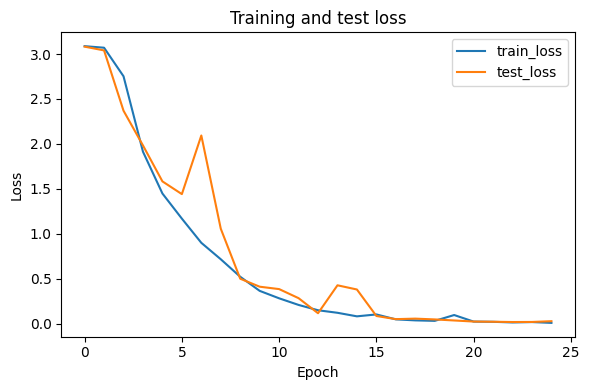

In [ ]:
from pathlib import Path
output_dir = Path("outputs_cnn_tutorial")

history = train(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    device=device,
)


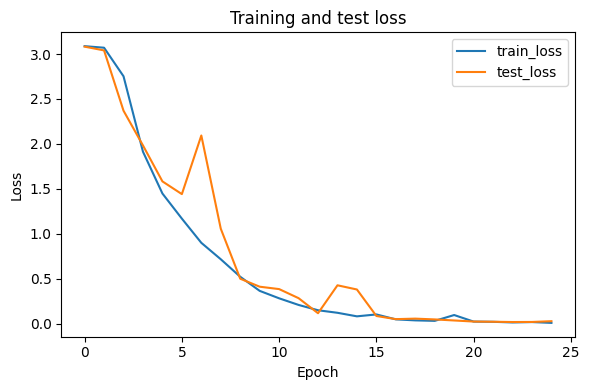

In [19]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train_loss")
plt.plot(history["test_loss"], label="test_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and test loss")
plt.legend()
plt.tight_layout()
# plt.savefig(output_dir / "03_loss_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

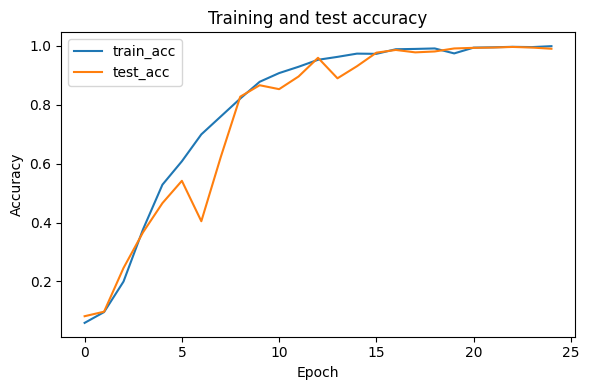

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_acc"], label="train_acc")
plt.plot(history["test_acc"], label="test_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and test accuracy")
plt.legend()
plt.tight_layout()
# plt.savefig(output_dir / "04_accuracy_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()


In [22]:
asl_train, asl_test = get_dataset(asl_dataset, THRESH)
classes = asl_train.label_to_idx
# print(lis_test)


train_loader = DataLoader(
        asl_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
)

test_loader = DataLoader(
        asl_test,
        batch_size=BATCH_SIZE,
        shuffle=False,
)


model = SignLanguageCNN(len(classes)).to(device)

In [23]:

from pathlib import Path
output_dir = Path("outputs_cnn_tutorial")

history = train(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    device=device,
)




Epoch 01/25 | train_loss=2.9121, train_acc=0.1561 | test_loss=2.0206, test_acc=0.3727
Epoch 02/25 | train_loss=1.2904, train_acc=0.5750 | test_loss=0.9483, test_acc=0.6688


KeyboardInterrupt: 

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_loss"], label="train_loss")
plt.plot(history["test_loss"], label="test_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and test loss")
plt.legend()
plt.tight_layout()
# plt.savefig(output_dir / "03_loss_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(history["train_acc"], label="train_acc")
plt.plot(history["test_acc"], label="test_acc")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and test accuracy")
plt.legend()
plt.tight_layout()
# plt.savefig(output_dir / "04_accuracy_curve.png", dpi=160, bbox_inches="tight")
plt.show()
plt.close()
